# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.


A line chart indexed to 1970 = 100. The question is about change over time relative to each continent’s starting size and lines show trends best. Indexing lets continents of very different sizes be compared fairly. Africa is the only continent in a saturated blue accent and every other continent is grey so the answer is visible at a glance. The palette used here is Blue and Grey because I thoougt it would be good to distinguisg between two sectors which has a great difference in population. Lines are labelled directly at their end points so the legend is removed and gridlines and axis clutter are kept to a minimum.

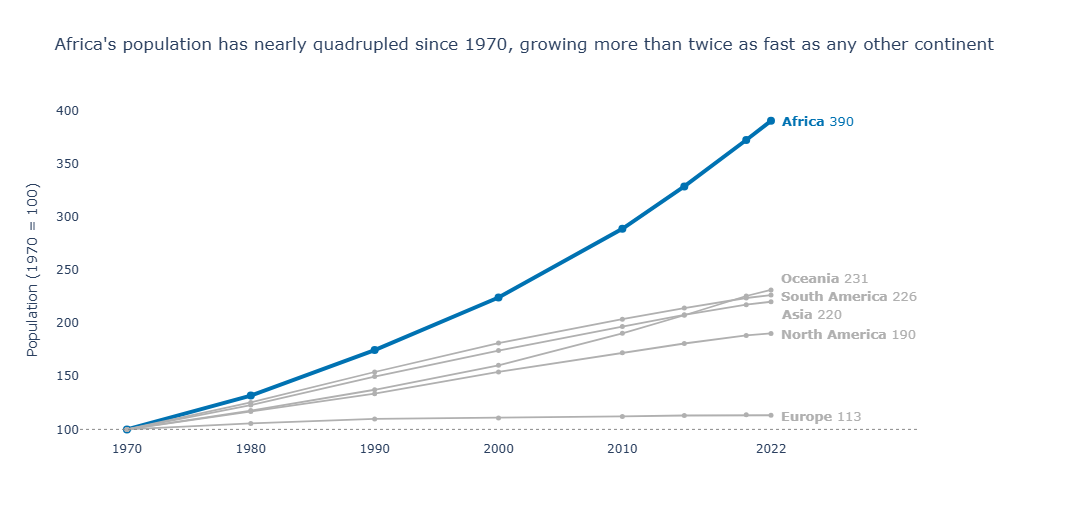

In [2]:
# Q1

cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base = cont[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Index'] = cont['Population'] / cont['Continent'].map(base) * 100

ACCENT, GREY = '#0072B2', '#B0B0B0'
colors = {c: (ACCENT if c == 'Africa' else GREY) for c in cont['Continent'].unique()}

fig = px.line(
    cont, x='Year', y='Index', color='Continent',
    color_discrete_map=colors, markers=True, template='plotly_white',
    title="Africa's population has nearly quadrupled since 1970, "
          "growing more than twice as fast as any other continent",
)
# Africa thick and blue, the rest thin and grey
fig.update_traces(line_width=1.8, marker_size=5)
fig.update_traces(line_width=4, marker_size=8, selector=dict(name='Africa'))

# (small vertical shifts stop Oceania / South America / Asia overlapping)
shift = {'Oceania': 12, 'South America': 0, 'Asia': -12}
last = cont[cont['Year'] == 2022]
for _, r in last.iterrows():
    fig.add_annotation(
        x=r['Year'], y=r['Index'], xanchor='left', xshift=8,
        yshift=shift.get(r['Continent'], 0), showarrow=False,
        text=f"<b>{r['Continent']}</b> {r['Index']:.0f}",
        font=dict(color=colors[r['Continent']], size=13),
    )
# Reference line at the 1970 baseline
fig.add_hline(y=100, line_dash='dot', line_color='#888', line_width=1)

fig.update_layout(
    showlegend=False, height=520, margin=dict(r=170),
    yaxis_title='Population (1970 = 100)', xaxis_title=None,
)
fig.update_xaxes(showgrid=False, tickvals=[1970, 1980, 1990, 2000, 2010, 2022])
fig.update_yaxes(showgrid=False, range=[90, 410])
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A sorted horizontal bar chart. The question asks for a ranking of the 15 countries that added the most people and bar length is the most accurate way to compare values on a common baseline. Sorting makes the order immediately readable and horizontal bars keep the country names legible. Africa is highlighted in blue while all other countries are grey so the second part of the question (how many are in Africa) can be answered at a glance. Bars are labelled directly with the number of people added (in millions) so the value axis and legend are removed.

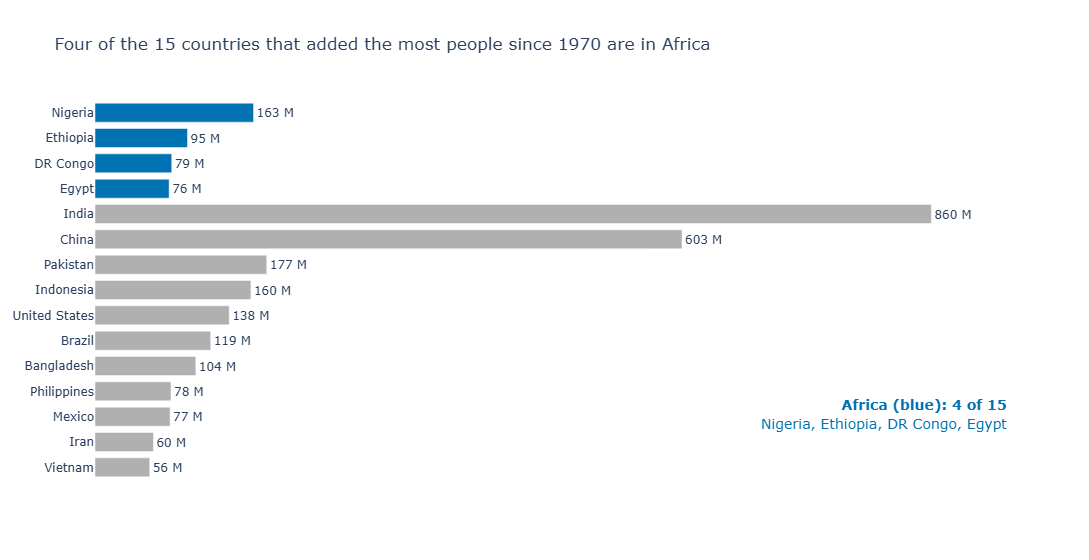

In [3]:
# Q2
d = df.copy()
d['Added'] = d['2022 Population'] - d['1970 Population']
top = d.nlargest(15, 'Added').sort_values('Added')          
top['Added_M'] = top['Added'] / 1e6
top['Group'] = np.where(top['Continent'] == 'Africa', 'Africa', 'Other')

ACCENT, GREY = '#0072B2', '#B0B0B0'

fig = px.bar(
    top, x='Added_M', y='Country', orientation='h', color='Group',
    color_discrete_map={'Africa': ACCENT, 'Other': GREY},
    text=top['Added_M'].map(lambda v: f'{v:,.0f} M'),
    template='plotly_white',
    title='Four of the 15 countries that added the most people since 1970 are in Africa',
)
fig.update_traces(textposition='outside', cliponaxis=False)
fig.update_layout(
    showlegend=False, height=560, margin=dict(r=60),
    xaxis_title=None, yaxis_title=None, bargap=0.25,
)
fig.update_xaxes(visible=False, range=[0, 960])
fig.update_yaxes(showgrid=False)

# Callout for the answer to the second part of the question
fig.add_annotation(
    x=0.98, y=0.12, xref='paper', yref='paper', xanchor='right', showarrow=False,
    text='<b>Africa (blue): 4 of 15</b><br>Nigeria, Ethiopia, DR Congo, Egypt',
    font=dict(color=ACCENT, size=14), align='right',
)
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A scatter plot because the question is about the relationship between two numeric variables (land area and 2022 population). Both axes are on a log scale values span from a few sq.km to 17 million sq.km and from a few hundred to 1.4 billion people so a linear scale would squash most countries into a corner. Colour encodes continent using a noraml palette, to show whether the pattern differs by region. A dashed grey line shows the overall trend and the countries furthest from it are labelled directly so the outliers can be read without hovering. The legend is placed above the plot and the gridlines are removed.

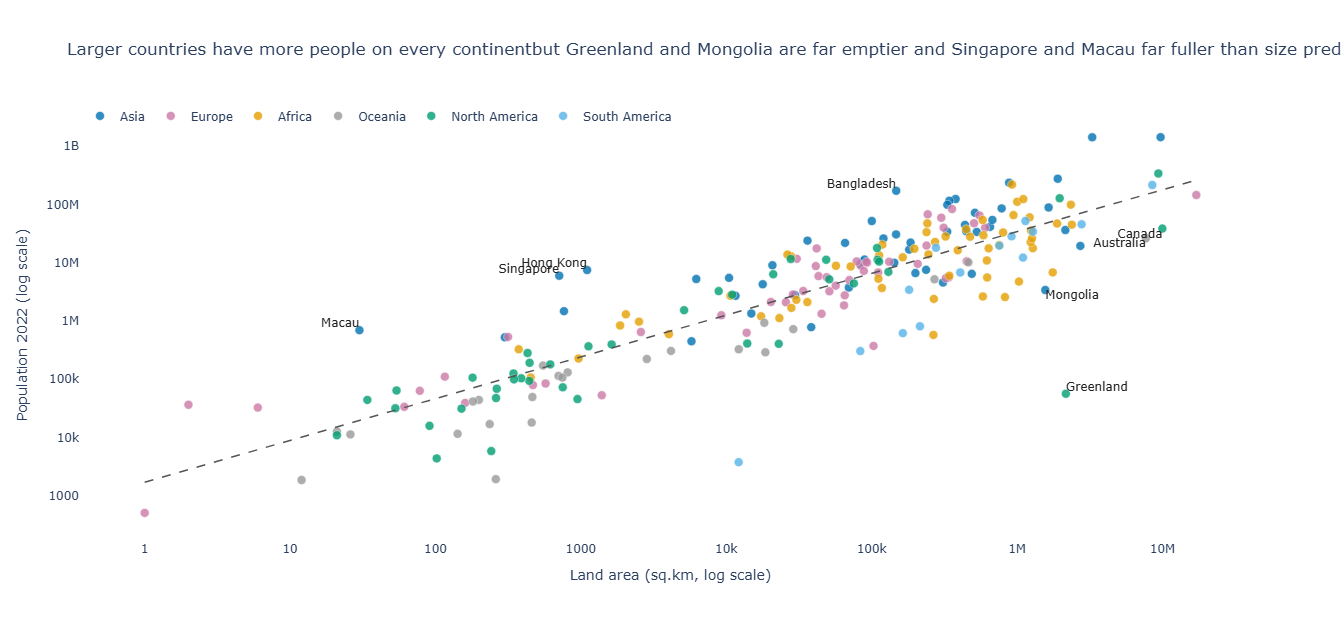

In [9]:
# Q3
import plotly.graph_objects as go

d = df.copy()
lx, ly = np.log10(d['Area']), np.log10(d['2022 Population'])
slope, intercept = np.polyfit(lx, ly, 1)

palette = {
    'Africa': '#E69F00', 'Asia': '#0072B2', 'Europe': '#CC79A7',
    'North America': '#009E73', 'Oceania': '#999999', 'South America': '#56B4E9',
}

fig = px.scatter(
    d, x='Area', y='2022 Population', color='Continent',
    color_discrete_map=palette, hover_name='Country', log_x=True, log_y=True,
    template='plotly_white', opacity=0.8,
    title='Larger countries have more people on every continent'
          'but Greenland and Mongolia are far emptier and Singapore and Macau far fuller than size predicts',
)
fig.update_traces(marker=dict(size=9, line=dict(width=0.5, color='white')))

# Overall trend line
xs = np.array([d['Area'].min(), d['Area'].max()])
fig.add_trace(go.Scatter(
    x=xs, y=10 ** (intercept + slope * np.log10(xs)), mode='lines',
    line=dict(color='#555', dash='dash', width=1.5), showlegend=False, hoverinfo='skip',
))

# Direct labels for the countries that break the pattern
labels = {
    'Greenland': 'top right', 'Mongolia': 'bottom right', 'Australia': 'bottom left',
    'Canada': 'bottom left', 'Singapore': 'top left', 'Hong Kong': 'top left',
    'Macau': 'top left', 'Bangladesh': 'top left',
}
lab = d[d['Country'].isin(labels)]
fig.add_trace(go.Scatter(
    x=lab['Area'], y=lab['2022 Population'], mode='text', text=lab['Country'],
    textposition=[labels[c] for c in lab['Country']],
    textfont=dict(size=12, color='#222'), showlegend=False, hoverinfo='skip',
))

fig.update_layout(
    height=620, legend=dict(orientation='h', y=1.02, x=0, title=None),
    xaxis_title='Land area (sq.km, log scale)',
    yaxis_title='Population 2022 (log scale)',
    margin=dict(t=110),
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A box plot per continent because the question asks for the spread of density within and across continents not just the average. Boxes show the median and quartiles and overlaying each country as a point shows the full distribution and the extreme outliers. A log scale is necessary because density ranges from 0.03 to over 23,000 people per sq.km on a linear axis nearly every box would be squashed flat. Continents are sorted by median density so the ranking is easy to read. Asia is highlighted in blue because it has the widest spread, and the other continents are grey. The most extreme countries are labelled directly and the legend and gridlines are removed.

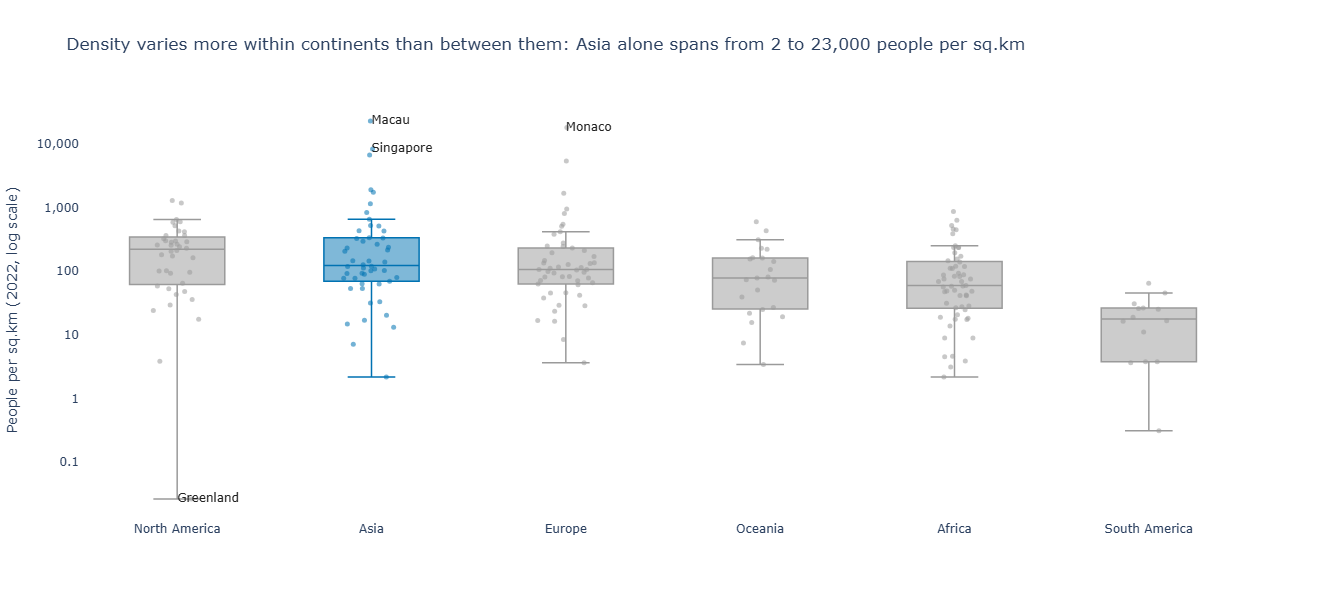

In [10]:
# Q4
d = df.copy()
order = d.groupby('Continent')['Density'].median().sort_values(ascending=False).index.tolist()
d['Group'] = np.where(d['Continent'] == 'Asia', 'Asia', 'Other')

ACCENT, GREY = '#0072B2', '#9A9A9A'

fig = px.box(
    d, x='Continent', y='Density', color='Group', points='all',
    hover_name='Country', category_orders={'Continent': order},
    color_discrete_map={'Asia': ACCENT, 'Other': GREY},
    log_y=True, template='plotly_white',
    title='Density varies more within continents than between them: '
          'Asia alone spans from 2 to 23,000 people per sq.km',
)
fig.update_traces(
    boxpoints='all', pointpos=0, jitter=0.6, marker=dict(size=5, opacity=0.55),
    line=dict(width=1.5), whiskerwidth=0.5,
)
fig.update_layout(boxmode='overlay')       

# Direct labels for the most extreme countries
ext = d[d['Country'].isin(['Macau', 'Monaco', 'Singapore', 'Greenland'])]
fig.add_trace(go.Scatter(
    x=ext['Continent'], y=ext['Density'], mode='text', text=ext['Country'],
    textposition='middle right', textfont=dict(size=12, color='#222'),
    showlegend=False, hoverinfo='skip',
))

fig.update_layout(
    showlegend=False, height=600,
    xaxis_title=None, yaxis_title='People per sq.km (2022, log scale)',
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False, tickvals=[0.01, 0.1, 1, 10, 100, 1000, 10000],
                 ticktext=['0.01', '0.1', '1', '10', '100', '1,000', '10,000'])
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A choropleth map because the question asks both which countries changed and where they are and only a map shows geography. The variable is the percentage change in population from 2000 to 2022 which makes countries of very different sizes comparable. A diverging colour scale is centred exactly on 0%: warm orange for shrinking countries, blue for growing ones and a neutral cream at zero. This pair is colour blind safe (no red/green) and the colour encodes direction not decoration. The scale is capped at +120% so that a few extreme cases (Qatar, UAE) do not wash out the rest. Land and map furniture use sand tones instead of grey and the map has no frame or coastlines to keep it uncluttered.

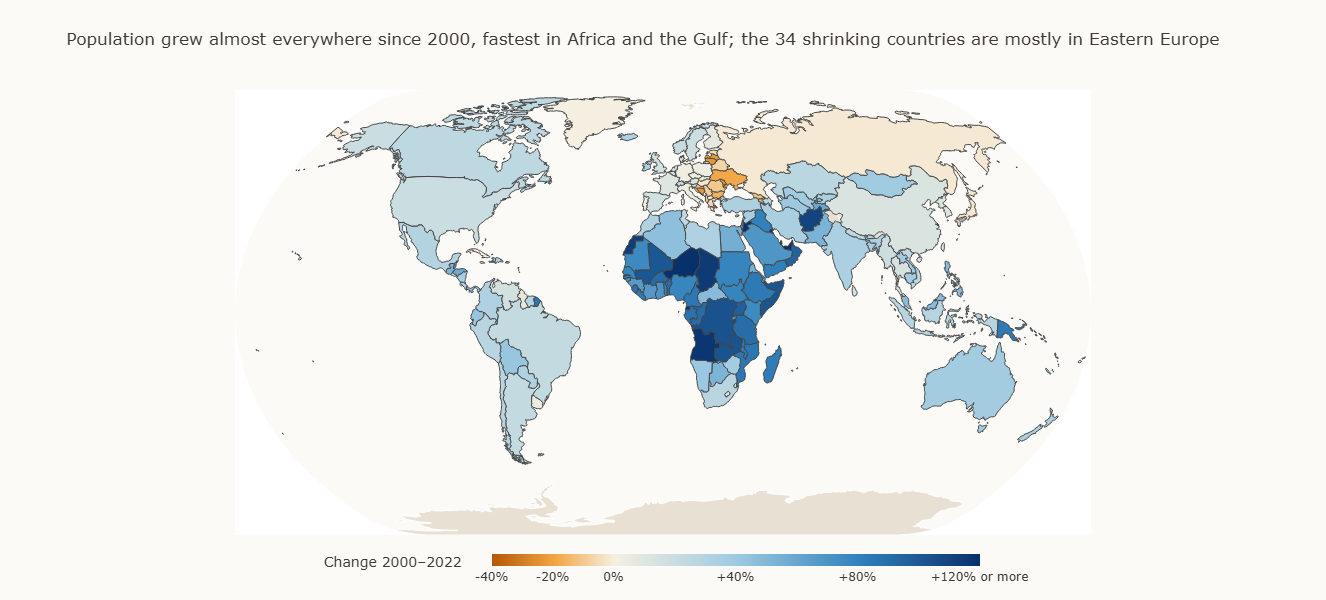

In [11]:
# Q5
d = df.copy()
d['Change'] = (d['2022 Population'] / d['2000 Population'] - 1) * 100

# Colour scale capped at -40% .. +120%, so 0% sits at 0.25 of the scale
CMIN, CMAX = -40, 120
zero = (0 - CMIN) / (CMAX - CMIN)                     
scale = [
    [0.0,   '#B35806'],  
    [0.125, '#F1A340'],  
    [zero,  '#F5EFE0'],  
    [0.5,   '#9ECAE1'],  
    [0.75,  '#3182BD'],
    [1.0,   '#08306B'],   
]

n_shrank = int((d['Change'] < 0).sum())

fig = px.choropleth(
    d, locations='CCA3', locationmode='ISO-3', color='Change',
    hover_name='Country', hover_data={'CCA3': False, 'Change': ':.1f'},
    color_continuous_scale=scale, range_color=[CMIN, CMAX],
    template='plotly_white',
    title=f'Population grew almost everywhere since 2000, fastest in Africa and the Gulf; '
          f'the {n_shrank} shrinking countries are mostly in Eastern Europe',
)

fig.update_geos(
    projection_type='natural earth',
    showframe=False, showcoastlines=False,
    showcountries=True, countrycolor='white',
    showland=True, landcolor='#E8E1D3',              
    showocean=True, oceancolor='#FBFAF7',
    showlakes=False,
)

fig.update_layout(
    height=600, margin=dict(l=10, r=10, t=90, b=10),
    paper_bgcolor='#FBFAF7', plot_bgcolor='#FBFAF7',
    font=dict(color='#3D3A35'),
    coloraxis_colorbar=dict(
        title='Change 2000–2022', orientation='h', len=0.5, thickness=12,
        x=0.5, xanchor='center', y=-0.02, yanchor='top',
        tickvals=[-40, -20, 0, 40, 80, 120],
        ticktext=['-40%', '-20%', '0%', '+40%', '+80%', '+120% or more'],
    ),
)
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A treemap because the question asks how the world population is distributed across two nested levels (continents and the countries within them) and asks to show both in one figure. Tile area is proportional to 2022 population so the share of any continent or country can be read directly and nesting preserves the hierarchy. Asia is highlighted in a colour blind safe blue because it holds most of the world’s people and all other continents use a neutral sand tone so colour carries the main finding instead of decorating. White borders separate the tiles. Labels show each tile’s share of the world total and tiles too small to hold a label are left unlabelled(the exact values are in the hover text).

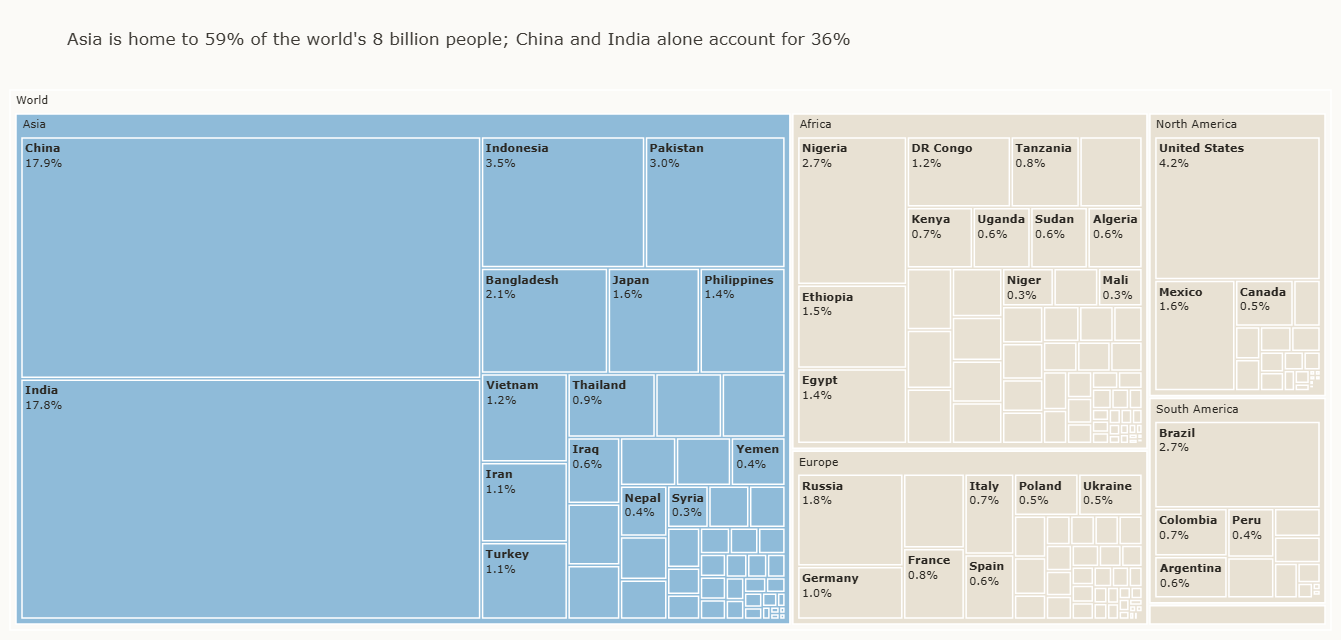

In [12]:
# Q6
d = df.copy()
d['Group'] = np.where(d['Continent'] == 'Asia', 'Asia', 'Other')

fig = px.treemap(
    d, path=[px.Constant('World'), 'Continent', 'Country'],
    values='2022 Population', color='Group',
    color_discrete_map={'Asia': '#8FBBD9', 'Other': '#E8E1D3', '(?)': '#FBFAF7'},
    template='plotly_white',
    title='Asia is home to 59% of the world\'s 8 billion people; '
          'China and India alone account for 36%',
)

fig.update_traces(
    texttemplate='<b>%{label}</b><br>%{percentRoot:.1%}',
    textfont=dict(color='#2B2823'),
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of world<extra></extra>',
    marker=dict(line=dict(color='white', width=1.5)),
    root_color='#FBFAF7',
    tiling=dict(pad=3),
)

fig.update_layout(
    height=640, margin=dict(l=10, r=10, t=90, b=10),
    paper_bgcolor='#FBFAF7',
    uniformtext=dict(minsize=11, mode='hide'),  
    font=dict(color='#3D3A35'),
)
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

A 100% stacked bar chart, because the question is about how shares of the world population (parts of a whole) changed across years. Each bar sums to 100% so the bars compare shares directly and population growth in absolute terms does not distract from the question. Africa (blue) is at the bottom and Europe (orange) at the top so the two segments that change most sit on the outer edges and are easy to compare; this pair is colour blind safe. Asia and the rest of the world use neutral sand tones because their shares barely move. Segments are labelled with their percentages and the groups are labelled directly at the right so no legend is needed. The years in the data are not evenly spaced (the last two are 2020 and 2022) so the x-axis treats each as a category.

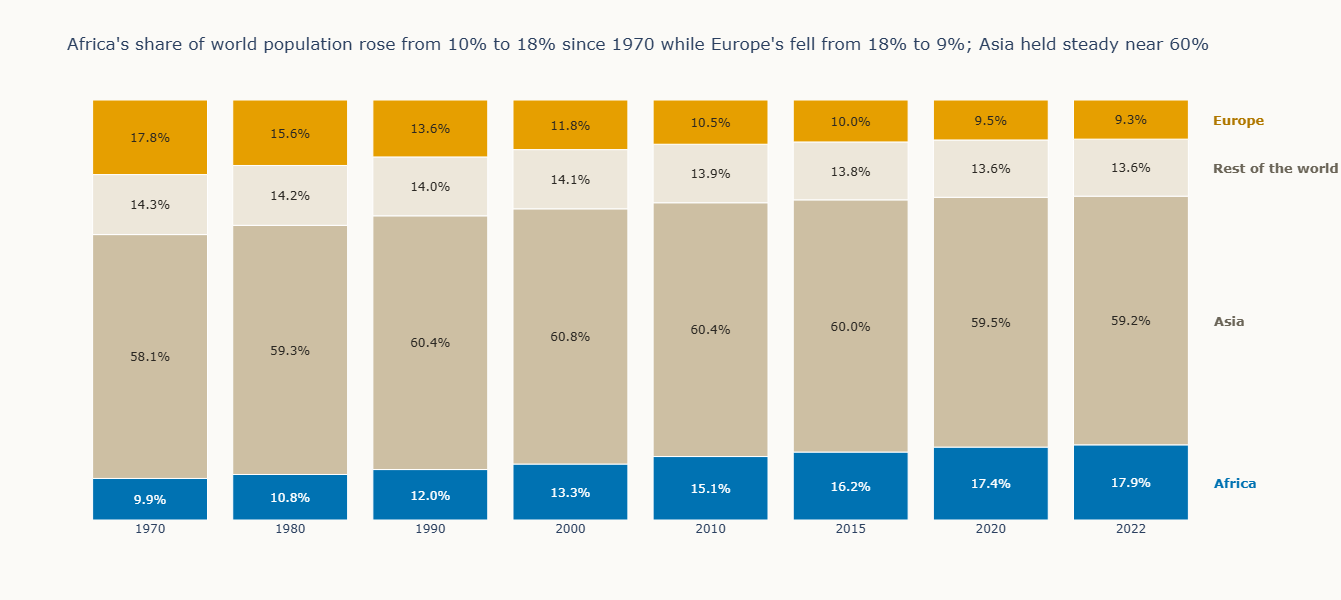

In [15]:
# Q7
d = df_long.copy()
d['Group'] = np.where(d['Continent'].isin(['Africa', 'Asia', 'Europe']),
                      d['Continent'], 'Rest of the world')

share = d.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum') * 100
share['Year'] = share['Year'].astype(str)             # category axis (years are unevenly spaced)

order = ['Africa', 'Asia', 'Rest of the world', 'Europe']   # bottom to top
colors = {'Africa': '#0072B2', 'Asia': '#CDBFA3',
          'Rest of the world': '#EDE7DA', 'Europe': '#E69F00'}

fig = px.bar(
    share, x='Year', y='Share', color='Group',
    category_orders={'Group': order, 'Year': sorted(share['Year'].unique())},
    color_discrete_map=colors, template='plotly_white',
    title="Africa's share of world population rose from 10% to 18% since 1970 "
          "while Europe's fell from 18% to 9%; Asia held steady near 60%",
)
fig.update_traces(
    texttemplate='%{y:.1f}%', textposition='inside', insidetextanchor='middle',
    textfont=dict(size=12, color='#2B2823'),
    marker=dict(line=dict(color='white', width=1)),
    hovertemplate='%{x}: %{y:.1f}%<extra>%{fullData.name}</extra>',
)
fig.update_traces(textfont=dict(size=12, color='white'), selector=dict(name='Africa'))

# Direct labels at the right edge of the plot, at each segment's 2022 midpoint
last = share[share['Year'] == '2022'].set_index('Group')['Share']
bottom = 0
for g in order:
    fig.add_annotation(
        x=1, xref='paper', xanchor='left', xshift=10,
        y=bottom + last[g] / 2, yref='y',
        text=f'<b>{g}</b>', showarrow=False,
        font=dict(size=13, color='#0072B2' if g == 'Africa'
                  else '#B07800' if g == 'Europe' else '#6B6558'),
    )
    bottom += last[g]

fig.update_layout(
    showlegend=False, height=600, bargap=0.18,
    margin=dict(r=140, t=100), xaxis_title=None, yaxis_title=None,
    paper_bgcolor='#FBFAF7', plot_bgcolor='#FBFAF7',
)
fig.update_xaxes(type='category', showgrid=False)     # <- the fix: stops Plotly treating years as dates
fig.update_yaxes(visible=False, range=[0, 100])
fig.show()